In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import os

In [2]:
results_dir = Path('/u/gongt/GLC7189_c_g0/kilosort4_220_940_nowhitening/sorter_output')

ops = np.load(results_dir/'ops.npy', allow_pickle=True).item()
camps = pd.read_csv(results_dir / 'cluster_Amplitude.tsv', sep='\t')['Amplitude'].values
contam_pct = pd.read_csv(results_dir / 'cluster_ContamPct.tsv', sep='\t')['ContamPct'].values
chan_map =  np.load(results_dir / 'channel_map.npy')
templates =  np.load(results_dir / 'templates.npy')
chan_best = (templates**2).sum(axis=1).argmax(axis=-1)
chan_best = chan_map[chan_best]
amplitudes = np.load(results_dir / 'amplitudes.npy')
st = np.load(results_dir / 'spike_times.npy')
clu = np.load(results_dir / 'spike_clusters.npy')
firing_rates = np.unique(clu, return_counts=True)[1] * 30000 / st.max()
dshift = ops['dshift']
fs = ops['fs']


In [3]:
print(templates.shape)

(379, 61, 369)


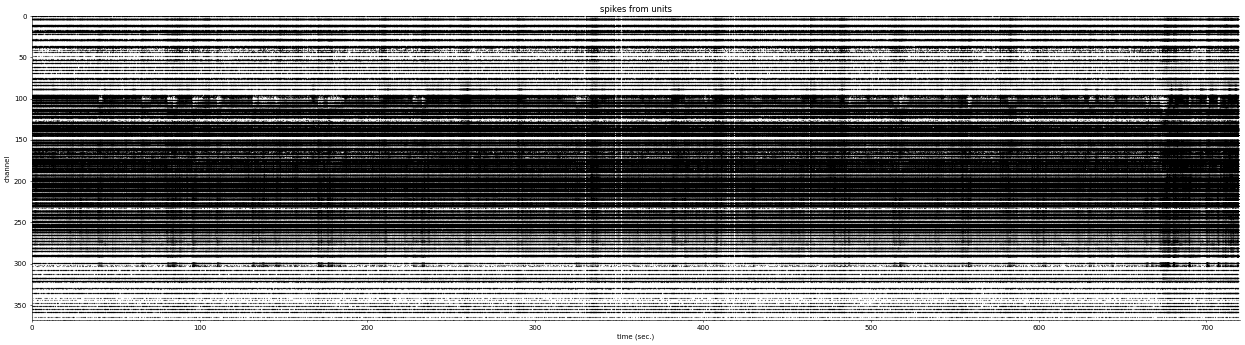

In [9]:
%matplotlib inline
import os
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np

rcParams['axes.spines.top'] = False
rcParams['axes.spines.right'] = False
gray = .5 * np.ones(3)

# ---- Figure 1: Drift plot ----

if np.any(dshift):
    fig1 = plt.figure(figsize=(5, 3))
    ax1 = fig1.add_subplot(111)
    ax1.plot(np.arange(0, ops['Nbatches']) * 2, dshift)
    ax1.set_xlabel('time (sec.)')
    ax1.set_ylabel('drift (um)')
    ax1.set_title('drift over time')
    plt.tight_layout()
    plt.savefig(os.path.join(results_dir, 'drift_plot.png'))

# ---- Figure 2: Raster plot ----
fig2 = plt.figure(figsize=(25, 7), dpi=50)
ax2 = fig2.add_subplot(111)
t0 = 0
t1 = np.nonzero(st > fs * 719)[0][0]
ax2.scatter(st[t0:t1] / 30000., chan_best[clu[t0:t1]], s=0.5, color='k', alpha=0.25)
ax2.set_xlim([0, 720])
ax2.set_ylim([chan_map.max(), 0])
ax2.set_xlabel('time (sec.)')
ax2.set_ylabel('channel')
ax2.set_title('spikes from units')
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'raster_plot.png'))